# 9 · Replication: a new day and a second device

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → [3 · Correction from counts](03_correction_from_counts.ipynb) → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb) → **9 · Replication**

**Question.** Notebook 8 showed the correction working on one device on one day. Is that result reproducible? Three
weeks later, on the same device, does the correction learned from real counts still recover the injected error? Does
the same pipeline work, with no tuning, on a second device it has never seen? Notebook 8 also left two questions
about the device's own errors: how the waiting error grows with time, and why dynamical decoupling (DD) fell short.

**The experiment.** On 25 October 2026, eleven jobs ran on `ibm_kingston` (the device of notebook 8) and on `ibm_fez`
(a second device of the same family, with a new six-qubit chain). As before, each job and its predicted outcome were
frozen and hashed before the job was sent. This notebook rebuilds every result from the raw counts in `data/`.
*Runtime: about 40 s.*

| jobs | device | what they measure |
|---|---|---|
| K0, K1, K2 | ibm_kingston | pilot; Round 1 (device, N1, the correction stored from 4 October, TOMO-9, waits of 4 / 8 / 16 µs); Round 2 (fresh corrections) |
| K3, K4 | ibm_kingston | DD at 8 µs with the idle message qubits pulsed (K3) or not pulsed (K4) |
| F0, F1, F2 | ibm_fez | pilot, Round 1 and Round 2 on the second device: no waits, no DD |
| G1 | ibm_fez | the device alone and the two corrections in **one** job (is "corrected above native" real?) |
| G2, G3 | ibm_kingston | TOMO-9 under DD at 4 / 8 / 16 µs; DD + a correction learned under DD |

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import time, math
import numpy as np
import matplotlib.pyplot as plt
from telecorr.hardware import data as D, replication as X
from telecorr.hardware.__main__ import check_replication
from telecorr.plotting import use_style, CONDITION, SLOTS, INK, INK_2, bar_labels
from telecorr.report import md_table, show, fmt
use_style()

t0 = time.time()
out = X.reproduce()                       # the whole replication analysis, from the raw counts
print(f"telecorr {telecorr.__version__}: replication analysis done in {time.time() - t0:.1f} s")
STATES = ("product_HT", "bell_30_70")
K1, K2, F1, F2 = out["K1"]["r1"]["tomo"], {b["block"]: b for b in out["K2"]["blocks"]}, out["F1"]["r1"]["tomo"], {b["block"]: b for b in out["F2"]["blocks"]}
crit_text = lambda c: c["criterion"].replace("REPLICATION ", "").replace(">=", "≥").replace("sigma", "σ")    # noqa: E731
OCT = {**D.reference("8d_round1.json")["r1"]["tomo"], **D.reference("8d_round2.json")["r2"]["tomo"]}    # 4 October (notebook 8)
LEGS = (("2", INK, "o"), ("3", INK_2, "s"))                  # the two channel legs: neutral ink, told apart by marker
OCT_KHZ = D.reference("8e_n2_analysis.json")["kHz"]                                                    # the 8 µs wait on 4 October

telecorr 1.1.0: replication analysis done in 21.1 s


## 1. The eleven jobs

Every job stayed under the time cap approved before it was sent, and used within 3 s of IBM's own detailed
estimate of its cost.

In [2]:
rows = [(j["job"], j["device"], j["circuits"], j["shots"], "yes" if j["dd"] else "no", j["estimate_detailed_s"], j["cap_s"], j["usage_s"])
        for j in out["jobs"]]
show(md_table(rows, ["job", "device", "circuits", "shots", "DD", "IBM estimate (s)", "cap (s)", "QPU time (s)"], 1))
show(f"Total: **{sum(j['usage_s'] for j in out['jobs'])} s** of QPU time. The IBM job ids are in `data/README.md`.")

| job | device | circuits | shots | DD | IBM estimate (s) | cap (s) | QPU time (s) |
|---|---|---|---|---|---|---|---|
| K0 | ibm_kingston | 12 | 6000 | no | 3.6 | 10 | 4 |
| K1 | ibm_kingston | 130 | 349000 | no | 92.2 | 116 | 95 |
| K2 | ibm_kingston | 54 | 126000 | no | 34.6 | 44 | 36 |
| K3 | ibm_kingston | 27 | 63000 | yes | 18.6 | 24 | 19 |
| K4 | ibm_kingston | 27 | 63000 | yes | 18.6 | 24 | 19 |
| F0 | ibm_fez | 10 | 5000 | no | 3.3 | 10 | 4 |
| F1 | ibm_fez | 58 | 160000 | no | 42.6 | 54 | 44 |
| F2 | ibm_fez | 27 | 72000 | no | 20.3 | 27 | 21 |
| G1 | ibm_fez | 54 | 108000 | no | 29.4 | 38 | 30 |
| G2 | ibm_kingston | 27 | 81000 | yes | 23.4 | 30 | 24 |
| G3 | ibm_kingston | 36 | 72000 | yes | 21.2 | 27 | 22 |

Total: **318 s** of QPU time. The IBM job ids are in `data/README.md`.

## 2. The same device, three weeks later

Round 1 (K1) measured the device alone, the injected error N1 of notebook 2 without correction, N1 with the
correction learned on 4 October and **stored unchanged**, and the TOMO-9 circuits that learn a fresh correction.
Round 2 (K2) ran the fresh correction. The pre-registered criteria were the ones of notebook 8: the corrected
fidelity reaches the device alone within 2σ, and the recovered fraction
f = (F_corr − F_none) / (F_native − F_none) is at least 0.9.

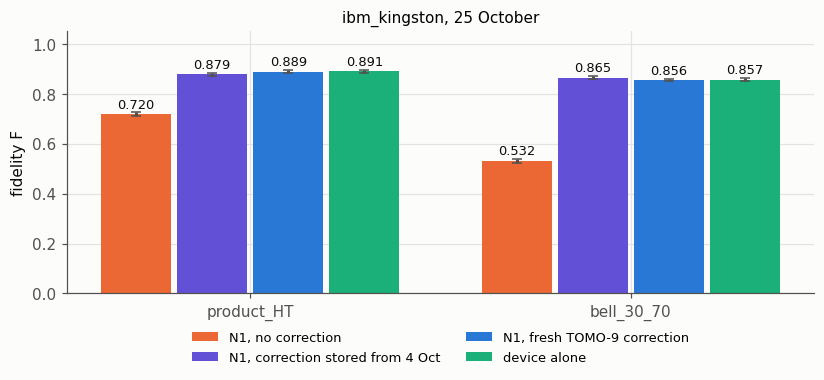

| message | day | F, device alone | F, N1 no correction | F, N1 + TOMO-9 correction | recovered fraction f |
|---|---|---|---|---|---|
| product_HT | 4 October (notebook 8) | 0.875 | 0.711 | 0.884 | 1.057 |
| product_HT | 25 October | 0.891 | 0.720 | 0.889 | 0.988 |
| bell_30_70 | 4 October (notebook 8) | 0.861 | 0.522 | 0.852 | 0.975 |
| bell_30_70 | 25 October | 0.857 | 0.532 | 0.856 | 0.998 |

| pre-registered criterion | value | limit |  |
|---|---|---|---|
| (product_HT): F ≥ F(native) - 2 σ | 0.889 | 0.873 | passes |
| (product_HT): recovered fraction ≥ 0.9 | 0.988 | 0.900 | passes |
| (bell_30_70): F ≥ F(native) - 2 σ | 0.856 | 0.842 | passes |
| (bell_30_70): recovered fraction ≥ 0.9 | 0.998 | 0.900 | passes |

**The result replicates.** The fresh correction recovers 98.8 % / 99.8 % of N1's loss (product_HT / bell_30_70). The correction stored from 4 October gives 0.879 / 0.865, against 0.889 / 0.856 for the fresh one: N1 is a fixed gate sequence, so a correction of it does not age.

In [3]:
order = [("R1_N1none", "no correction", "N1, no correction"), ("R1_N1old", "stored correction (4 Oct)", "N1, correction stored from 4 Oct"),
         ("R2_N1corr", "TOMO-9 correction", "N1, fresh TOMO-9 correction"), ("R1_nativeA", "native (no injected noise)", "device alone")]
def FK(pre, st):
    k = f"{pre}_{st}"
    return (K1.get(k) or K2[k]), K1.get(k, {}).get("F_sigma") or K2.get(k, {}).get("sigma")
fig, ax = plt.subplots(figsize=(7.6, 3.6)); w = 0.2
for i, (pre, cond, name) in enumerate(order):
    v = [FK(pre, st) for st in STATES]
    bars = ax.bar(np.arange(2) + (i - 1.5) * w, [x[0]["F"] for x in v], w * 0.92, yerr=[x[1] for x in v],
                  color=CONDITION[cond], label=name, capsize=3, ecolor=INK_2)
    bar_labels(ax, bars, pad=0.012)
ax.set_xticks(range(2), STATES); ax.set_ylim(0, 1.05); ax.set_ylabel("fidelity F")
ax.set_title("ibm_kingston, 25 October", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=8.5); plt.tight_layout(); plt.show()

rows = []
for st in STATES:
    rows.append((st, "4 October (notebook 8)", OCT[f"R1_nativeA_{st}"]["F"], OCT[f"R1_N1none_{st}"]["F"], OCT[f"R2_N1corr_{st}"]["F"],
                 (OCT[f"R2_N1corr_{st}"]["F"] - OCT[f"R1_N1none_{st}"]["F"]) / (OCT[f"R1_nativeA_{st}"]["F"] - OCT[f"R1_N1none_{st}"]["F"])))
    rows.append((st, "25 October", K1[f"R1_nativeA_{st}"]["F"], K1[f"R1_N1none_{st}"]["F"], K2[f"R2_N1corr_{st}"]["F"],
                 K2[f"R2_N1corr_{st}"]["recovered_fraction"]))
show(md_table(rows, ["message", "day", "F, device alone", "F, N1 no correction", "F, N1 + TOMO-9 correction", "recovered fraction f"], 3))
show(md_table([(crit_text(c), c["value"], c["limit"], "passes" if c["ok"] else "**fails**")
               for c in out["K2"]["criteria"] if c["criterion"].startswith("REPLICATION")], ["pre-registered criterion", "value", "limit", ""], 3))
show("**The result replicates.** The fresh correction recovers " + " / ".join(f"{100 * K2[f'R2_N1corr_{st}']['recovered_fraction']:.1f} %" for st in STATES)
     + " of N1's loss (product_HT / bell_30_70). The correction stored from 4 October gives "
     + " / ".join(f"{K1[f'R1_N1old_{st}']['F']:.3f}" for st in STATES) + ", against " + " / ".join(f"{K2[f'R2_N1corr_{st}']['F']:.3f}" for st in STATES)
     + " for the fresh one: N1 is a fixed gate sequence, so a correction of it does not age.")

## 3. A second device, with no tuning

On `ibm_fez` the same pipeline ran on a new chain chosen by the same rule: F1 measured the device, N1 and TOMO-9; F2
ran the correction learned from F1's counts. Nothing was adjusted for the new device.

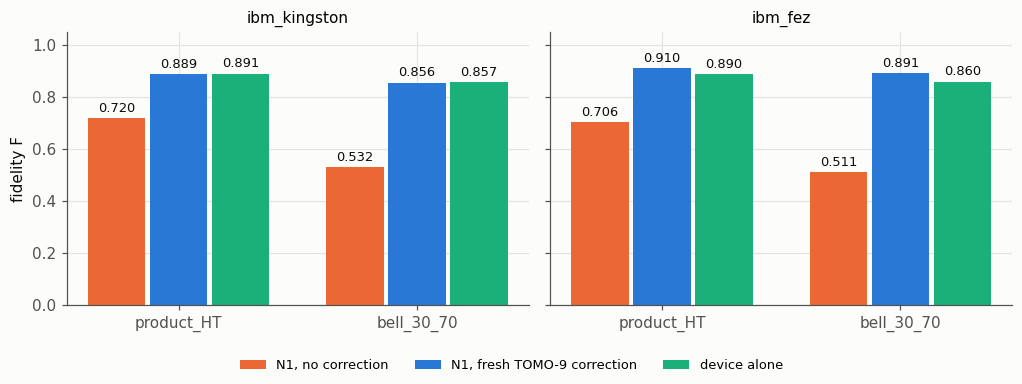

| pre-registered criterion (ibm_fez) | value | limit |  |
|---|---|---|---|
| (product_HT): F ≥ F(native) - 2 σ | 0.910 | 0.872 | passes |
| (product_HT): recovered fraction ≥ 0.9 | 1.114 | 0.900 | passes |
| (bell_30_70): F ≥ F(native) - 2 σ | 0.891 | 0.846 | passes |
| (bell_30_70): recovered fraction ≥ 0.9 | 1.089 | 0.900 | passes |

**The method transfers.** On Fez, N1 lowers F to 0.706 / 0.511 and the correction learned from Fez's own counts brings it to 0.910 / 0.891. Both values are *above* Fez's device alone (0.890 / 0.860, f > 1). Section 4 tests whether that is real.

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9.4, 3.5), sharey=True)
for ax, (dev, T1, T2) in zip(axs, (("ibm_kingston", K1, K2), ("ibm_fez", F1, F2))):
    for i, (pre, cond, name) in enumerate([order[0], order[2], order[3]]):
        vals = [(T1.get(f"{pre}_{st}") or T2[f"{pre}_{st}"])["F"] for st in STATES]
        bars = ax.bar(np.arange(2) + (i - 1) * 0.26, vals, 0.24, color=CONDITION[cond], label=name)
        bar_labels(ax, bars, pad=0.012)
    ax.set_xticks(range(2), STATES); ax.set_ylim(0, 1.05); ax.set_title(dev, fontsize=10)
axs[0].set_ylabel("fidelity F")
h, l = axs[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, fontsize=8.5)
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()
show(md_table([(crit_text(c), c["value"], c["limit"], "passes" if c["ok"] else "**fails**") for c in out["F2"]["criteria"]],
              ["pre-registered criterion (ibm_fez)", "value", "limit", ""], 3))
show("**The method transfers.** On Fez, N1 lowers F to " + " / ".join(f"{F1[f'R1_N1none_{st}']['F']:.3f}" for st in STATES)
     + " and the correction learned from Fez's own counts brings it to " + " / ".join(f"{F2[f'R2_N1corr_{st}']['F']:.3f}" for st in STATES)
     + ". Both values are *above* Fez's device alone (" + " / ".join(f"{F1[f'R1_nativeA_{st}']['F']:.3f}" for st in STATES)
     + ", f > 1). Section 4 tests whether that is real.")

## 4. Is "corrected above native" real? Both in one job (G1)

F1 and F2 were two jobs, so the device can drift between them. G1 ran the device alone,
N1 + F1's correction, and the device + its own *fingerprint* correction (TOMO-9 of the device alone) interleaved in
**one** job. The same-job difference D = F(corrected) − F(device alone) has no drift between jobs in it. Two
hypotheses were written down before G1 was sent: REAL (D equals F2 − F1, as seen in two jobs) and DRIFT (D equals
model 2's prediction).

In [5]:
rows = [(t["state"], t["comparison"].replace(" - native (same job)", " − device alone").replace("N1 + correction", "N1 + F1's correction"),
         f"{t['D']:+.3f}", t["sigma"], t["z"], t.get("REAL"), t.get("DRIFT")) for t in out["G1"]["tests"]]
show(md_table(rows, ["message", "same-job difference D", "D", "σ", "D / σ", "REAL (predicted)", "DRIFT (predicted)"], 3))
t = {(r["state"], r["comparison"][:2]): r for r in out["G1"]["tests"]}
show(f"* **product_HT: drift.** D = {t[('product_HT', 'N1')]['D']:+.3f} ± {t[('product_HT', 'N1')]['sigma']:.3f}: in one job the corrected "
     "block equals the device alone. The two-job excess came from the device changing between F1 and F2.\n"
     f"* **bell_30_70: real.** D = {t[('bell_30_70', 'N1')]['D']:+.3f} ± {t[('bell_30_70', 'N1')]['sigma']:.3f} "
     f"({t[('bell_30_70', 'N1')]['z']:.1f}σ). The fingerprint correction alone adds {t[('bell_30_70', 'fi')]['D']:+.3f} ± "
     f"{t[('bell_30_70', 'fi')]['sigma']:.3f} ({t[('bell_30_70', 'fi')]['z']:.1f}σ): TOMO-9 also removes a coherent rotation "
     "that belongs to Fez itself, and the entangled message is the one that feels it.")

| message | same-job difference D | D | σ | D / σ | REAL (predicted) | DRIFT (predicted) |
|---|---|---|---|---|---|---|
| product_HT | N1 + F1's correction − device alone | +0.002 | 0.011 | 0.207 | 0.021 | -0.002 |
| product_HT | fingerprint correction − device alone | +0.001 | 0.011 | 0.089 | - | - |
| bell_30_70 | N1 + F1's correction − device alone | +0.024 | 0.008 | 2.801 | 0.031 | -0.012 |
| bell_30_70 | fingerprint correction − device alone | +0.039 | 0.009 | 4.542 | - | - |

* **product_HT: drift.** D = +0.002 ± 0.011: in one job the corrected block equals the device alone. The two-job excess came from the device changing between F1 and F2.
* **bell_30_70: real.** D = +0.024 ± 0.008 (2.8σ). The fingerprint correction alone adds +0.039 ± 0.009 (4.5σ): TOMO-9 also removes a coherent rotation that belongs to Fez itself, and the entangled message is the one that feels it.

## 5. The waiting error at 4, 8 and 16 µs

Notebook 8 found that an 8 µs wait mostly rotates each channel qubit about −z: a frequency offset. K1 measured
TOMO-9 at three waits, K2 corrected each one. If the offset is a fixed frequency f, the angle is θ = 2π f t.

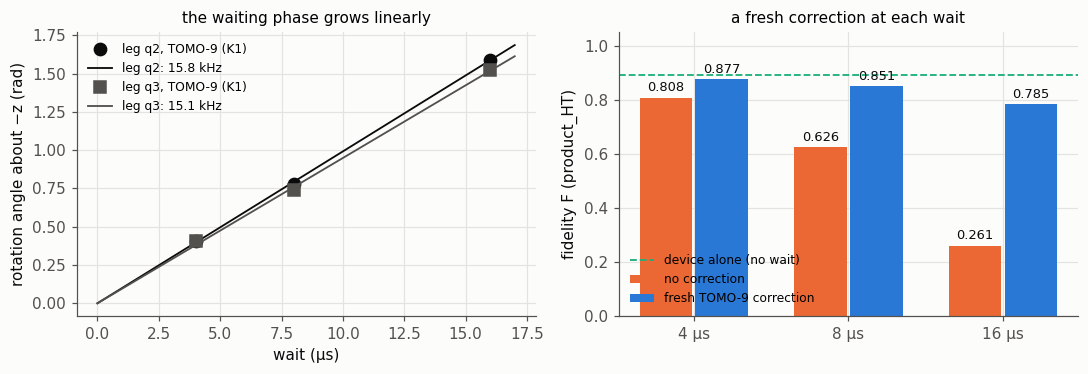

| wait | gain F(corrected) − F(none) | σ | gain / σ |
|---|---|---|---|
| 4 µs | 0.069 | 0.011 | 6.044 |
| 8 µs | 0.225 | 0.011 | 19.713 |
| 16 µs | 0.524 | 0.011 | 48.931 |

The fit through the origin leaves residuals below 0.026 rad, so the phase is linear in the wait. Its frequency has **drifted since 4 October**: both legs are now near 15 kHz (15.8 / 15.1 kHz; 12.8 / 22.3 kHz on 4 October). A correction learned on another day would be wrong; a fresh TOMO-9 fixes every wait, at 16 µs from 0.261 to 0.785. The incoherent part is small today: from 8 to 16 µs the x / y shrink of leg q2 falls only from 0.90 / 0.83 to 0.85 / 0.80.

In [6]:
w = out["wait_khz"]; t9 = out["K1"]["r1"]["tomo9"]; tt = np.linspace(0, 17, 50)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for q, c, mk in LEGS:
    axs[0].plot(w["t_us"], w[f"angles_q{q}"], mk, color=c, ms=8, label=f"leg q{q}, TOMO-9 (K1)")
    axs[0].plot(tt, 2 * np.pi * w[f"q{q}"] * 1e-3 * tt, "-", color=c, lw=1.2, label=f"leg q{q}: {w[f'q{q}']:.1f} kHz")
axs[0].set_xlabel("wait (µs)"); axs[0].set_ylabel("rotation angle about −z (rad)"); axs[0].legend(fontsize=8)
axs[0].set_title("the waiting phase grows linearly", fontsize=10)
taus = ("4us", "8us", "16us"); x = np.arange(3)
none = [K1[f"R1_N2none{t}_product_HT"]["F"] for t in taus]; corr = [K2[f"R2_N2corr{t}_product_HT"]["F"] for t in taus]
for i, (vals, cond, name) in enumerate(((none, "no correction", "no correction"), (corr, "TOMO-9 correction", "fresh TOMO-9 correction"))):
    bars = axs[1].bar(x + (i - 0.5) * 0.36, vals, 0.34, color=CONDITION[cond], label=name); bar_labels(axs[1], bars, pad=0.012)
axs[1].axhline(K1["R1_nativeA_product_HT"]["F"], color=CONDITION["native (no injected noise)"], lw=1.2, ls="--", label="device alone (no wait)")
axs[1].set_xticks(x, ["4 µs", "8 µs", "16 µs"]); axs[1].set_ylim(0, 1.05); axs[1].set_ylabel("fidelity F (product_HT)")
axs[1].legend(fontsize=8, loc="lower left"); axs[1].set_title("a fresh correction at each wait", fontsize=10)
plt.tight_layout(); plt.show()
rows = [(t.replace("us", " µs"), K2[f"R2_N2corr{t}_product_HT"]["gain"], K2[f"R2_N2corr{t}_product_HT"]["gain_sigma"],
         K2[f"R2_N2corr{t}_product_HT"]["gain"] / K2[f"R2_N2corr{t}_product_HT"]["gain_sigma"]) for t in taus]
show(md_table(rows, ["wait", "gain F(corrected) − F(none)", "σ", "gain / σ"], 3))
s8 = {q: t9["calN28us"][f"shrink_{q}"] for q in (2, 3)}; s16 = {q: t9["calN216us"][f"shrink_{q}"] for q in (2, 3)}
show(f"The fit through the origin leaves residuals below {max(abs(r) for q in (2, 3) for r in w[f'residuals_q{q}']):.3f} rad, so the phase is "
     f"linear in the wait. Its frequency has **drifted since 4 October**: both legs are now near 15 kHz "
     f"({w['q2']:.1f} / {w['q3']:.1f} kHz; {OCT_KHZ['2']:.1f} / {OCT_KHZ['3']:.1f} kHz on 4 October). A correction learned on another day would be wrong; "
     f"a fresh TOMO-9 fixes every wait, at 16 µs from {none[2]:.3f} to {corr[2]:.3f}. The incoherent part is small today: from 8 to 16 µs the "
     f"x / y shrink of leg q2 falls only from {s8[2][0]:.2f} / {s8[2][1]:.2f} to {s16[2][0]:.2f} / {s16[2][1]:.2f}.")

## 6. Dynamical decoupling: Part 9.8's spectator test (K3, K4)

Notebook 8 explained DD's shortfall without a free parameter: IBM's DD also pulses the idle message qubits, and each
pulsed neighbour adds a phase π ζ t to its channel qubit through the static ZZ coupling ζ. K3 used IBM's default
(message qubits pulsed), K4 the option that leaves qubits still in |0⟩ alone. The model predicts the z rotation that
TOMO-9 finds under DD: π ζ t in K3 and **zero** in K4.

In [7]:
z3 = {r["leg"]: r for r in out["K3"]["rotation"]}; z4 = {r["leg"]: r for r in out["K4"]["rotation"]}
rows = []
for q in ("q2", "q3"):
    rows.append((q, z3[q]["z measured (rad)"], z3[q]["sigma"], z3[q]["z model 2 (rad)"], z4[q]["z measured (rad)"], z4[q]["sigma"], z4[q]["z model 2 (rad)"],
                 z3[q]["z measured (rad)"] - z4[q]["z measured (rad)"]))
show(md_table(rows, ["leg", "K3 z (rad)", "σ", "K3 model", "K4 z (rad)", "σ", "K4 model", "K3 − K4"], 3))
b3 = {b["block"]: b for b in out["K3"]["blocks"]}; b4 = {b["block"]: b for b in out["K4"]["blocks"]}
gap = b4["R4_DDUcorr_product_HT"]["F"] - b3["R3_DDcorr_product_HT"]["F"]
gs = math.hypot(b4["R4_DDUcorr_product_HT"]["sigma"], b3["R3_DDcorr_product_HT"]["sigma"])
gp = b4["R4_DDUcorr_product_HT"]["model_2"] - b3["R3_DDcorr_product_HT"]["model_2"]
show(f"* **As a difference, the model holds.** K3 − K4 = {rows[0][7]:+.3f} / {rows[1][7]:+.3f} rad, against π ζ t = "
     f"{rows[0][3]:.3f} / {rows[1][3]:.3f}. K1's correction + DD is {gap:+.3f} ± {gs:.3f} better without spectator pulses, against {gp:+.3f} predicted.\n"
     f"* **As an absolute prediction, it fails.** Without spectator pulses DD still leaves {rows[0][4]:+.3f} / {rows[1][4]:+.3f} rad "
     f"({z4['q2']['pull']:.0f}σ / {z4['q3']['pull']:.0f}σ from zero). Something else rotates the qubits under DD; G2 asks how it grows.")

| leg | K3 z (rad) | σ | K3 model | K4 z (rad) | σ | K4 model | K3 − K4 |
|---|---|---|---|---|---|---|---|
| q2 | 0.199 | 0.016 | 0.114 | 0.091 | 0.016 | 0.000 | 0.108 |
| q3 | 0.191 | 0.017 | 0.127 | 0.081 | 0.016 | 0.000 | 0.111 |

* **As a difference, the model holds.** K3 − K4 = +0.108 / +0.111 rad, against π ζ t = 0.114 / 0.127. K1's correction + DD is +0.059 ± 0.011 better without spectator pulses, against +0.056 predicted.
* **As an absolute prediction, it fails.** Without spectator pulses DD still leaves +0.091 / +0.081 rad (6σ / 5σ from zero). Something else rotates the qubits under DD; G2 asks how it grows.

## 7. Where DD's extra rotation comes from (G2) and whether a correction can remove it (G3)

G2 measured TOMO-9 under DD (message qubits not pulsed) at 4, 8 and 16 µs in one job. Two hypotheses were written down
first: CONST (a fixed error per DD block: z the same at every wait) and LINEAR (a phase DD does not refocus: z ∝ t).
A straight line z(t) = a + b t is fitted on each leg.

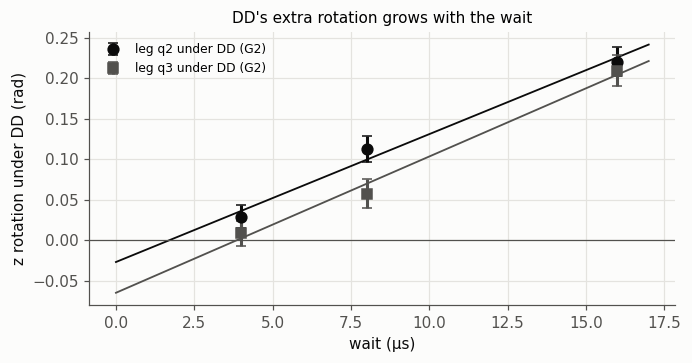

| leg | intercept a (rad) | σ | slope (kHz) | slope / σ | reading (pre-registered rule) |
|---|---|---|---|---|---|
| q2 | -0.027 | 0.019 | 2.514 | 8.237 | LINEAR |
| q3 | -0.065 | 0.020 | 2.680 | 8.165 | undecided |

The slope is 8.2σ / 8.2σ from zero, so CONST is ruled out. Leg q2 reads LINEAR; leg q3 is formally undecided because its intercept is also 3.2σ from zero. Where the extra 2.5 / 2.7 kHz comes from is not known.

In [8]:
G2 = out["G2"]; tt = np.linspace(0, 17, 50)
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for q, c, mk in LEGS:
    r = [x for x in G2["rotation"] if x["leg"] == "q" + q]
    ax.errorbar([4, 8, 16], [x["z measured (rad)"] for x in r], yerr=[x["sigma"] for x in r], fmt=mk, color=c, ms=7, capsize=3,
                label=f"leg q{q} under DD (G2)")
    f = G2["fits"]["q" + q]; ax.plot(tt, f["a_rad"] + f["b_rad_per_us"] * tt, "-", color=c, lw=1.2)
ax.axhline(0, color=INK_2, lw=0.8); ax.set_xlabel("wait (µs)"); ax.set_ylabel("z rotation under DD (rad)")
ax.legend(fontsize=8); ax.set_title("DD's extra rotation grows with the wait", fontsize=10); plt.tight_layout(); plt.show()
rows = [(q, f["a_rad"], f["a_sigma"], f["b_rad_per_us"] / (2 * np.pi) * 1e3, f["b_rad_per_us"] / f["b_sigma"],
         "LINEAR" if f["LINEAR favoured (a ~ 0)"] and not f["CONST favoured (b ~ 0)"] else ("CONST" if f["CONST favoured (b ~ 0)"] else "undecided"))
        for q, f in G2["fits"].items()]
show(md_table(rows, ["leg", "intercept a (rad)", "σ", "slope (kHz)", "slope / σ", "reading (pre-registered rule)"], 3))
f2, f3 = G2["fits"]["q2"], G2["fits"]["q3"]
show(f"The slope is {f2['b_rad_per_us'] / f2['b_sigma']:.1f}σ / {f3['b_rad_per_us'] / f3['b_sigma']:.1f}σ from zero, so CONST is ruled out. "
     f"Leg q2 reads LINEAR; leg q3 is formally undecided because its intercept is also {abs(f3['a_rad']) / f3['a_sigma']:.1f}σ from zero. "
     f"Where the extra {rows[0][3]:.1f} / {rows[1][3]:.1f} kHz comes from is not known.")

G3 then asked whether a correction **learned under DD** (from G2's TOMO-9) removes this rotation: DD alone and DD + that
correction at 8 and 16 µs, in one job. The pre-registered criterion G3-A was a gain above 3σ at both waits.

In [9]:
G3_TEXT = {"G3-A": "DD + correction − DD alone (G3-A: gain > 3σ)", "G3-B": "DD + correction − K2's fresh correction without DD (G3-B)"}
rows = [(c["criterion"].split()[1].replace(":", "").replace("us", " µs"), G3_TEXT[c["criterion"][:4]], f"{c['value']:+.3f}", c["sigma"], c["z"],
         ("passes" if c["ok"] else "**fails**") if c["ok"] is not None else c["reading"]) for c in out["G3"]["criteria"]]
show(md_table(rows, ["wait", "comparison (pre-registered)", "difference", "σ", "z", "outcome"], 3))
g3 = {b["block"]: b["F"] for b in out["G3"]["blocks"]}
STRAT = [("fresh TOMO-9 correction, no DD (K2)", K2["R2_N2corr8us_product_HT"]["F"]),
         ("DD alone, message qubits not pulsed (K4)", b4["R4_DDUnone_product_HT"]["F"]),
         ("DD + a correction learned under DD (G3)", g3["R7_DDU8uscorr_product_HT"]),
         ("DD alone, message qubits pulsed (K3)", b3["R3_DDnone_product_HT"]["F"]),
         ("a correction learned without DD, then DD (K4 / K3)", f"{b3['R3_DDcorr_product_HT']['F']:.3f}–{b4['R4_DDUcorr_product_HT']['F']:.3f}"),
         ("no correction, no DD (K1)", K1["R1_N2none8us_product_HT"]["F"])]
show("**The strategies at an 8 µs wait** (product_HT):")
show(md_table(STRAT, ["strategy", "F"], 3))
dt_h = {j["job"]: j["created"] for j in out["jobs"]}
show(f"DD alone at 8 µs gave {b4['R4_DDUnone_product_HT']['F']:.3f} in K4 and {g3['R7_DDU8usnone_product_HT']:.3f} in G3, the same circuits "
     f"{(np.datetime64(dt_h['G3'][:19]) - np.datetime64(dt_h['K4'][:19])) / np.timedelta64(1, 'm'):.0f} minutes apart: between two jobs the device "
     "drifts by about this much, more than the shot noise. This is why the same-job designs (G1, G2, G3) are the more reliable ones.")
show("On these devices DD is not a free improvement: its spectator phase is real, it leaves a phase that grows with the "
     "wait, and it costs coherence that no correction can give back. The best fix for the wait is a fresh TOMO-9 "
     "correction without DD.")

| wait | comparison (pre-registered) | difference | σ | z | outcome |
|---|---|---|---|---|---|
| 8 µs | DD + correction − DD alone (G3-A: gain > 3σ) | -0.002 | 0.011 | -0.224 | **fails** |
| 8 µs | DD + correction − K2's fresh correction without DD (G3-B) | -0.070 | 0.011 | -6.578 | worse |
| 16 µs | DD + correction − DD alone (G3-A: gain > 3σ) | +0.025 | 0.012 | 2.194 | **fails** |
| 16 µs | DD + correction − K2's fresh correction without DD (G3-B) | -0.054 | 0.011 | -4.883 | worse |

**The strategies at an 8 µs wait** (product_HT):

| strategy | F |
|---|---|
| fresh TOMO-9 correction, no DD (K2) | 0.851 |
| DD alone, message qubits not pulsed (K4) | 0.815 |
| DD + a correction learned under DD (G3) | 0.780 |
| DD alone, message qubits pulsed (K3) | 0.778 |
| a correction learned without DD, then DD (K4 / K3) | 0.524–0.583 |
| no correction, no DD (K1) | 0.626 |

DD alone at 8 µs gave 0.815 in K4 and 0.783 in G3, the same circuits 59 minutes apart: between two jobs the device drifts by about this much, more than the shot noise. This is why the same-job designs (G1, G2, G3) are the more reliable ones.

On these devices DD is not a free improvement: its spectator phase is real, it leaves a phase that grows with the wait, and it costs coherence that no correction can give back. The best fix for the wait is a fresh TOMO-9 correction without DD.

## 8. How good were the predictions?

Every prediction was written and hashed before its job was sent. *Model 2* is the twirl model of notebook 2: each leg
reaches Bob as diag(R T), with T from the job's own Round 1 TOMO-9 (recomputed here from the counts). *Model 1*, the
twin built from IBM's calibration record, is shipped as saved values only.

In [10]:
rows = []
for job, B in (("K2", out["K2"]["blocks"]), ("F2", out["F2"]["blocks"]), ("G1", out["G1"]["blocks"]), ("K3", out["K3"]["blocks"]),
               ("K4", out["K4"]["blocks"]), ("G3", out["G3"]["blocks"])):
    for b_ in B:
        name, st = X.describe(b_["block"])
        rows.append((job, name, st, b_["F"], b_["sigma"], b_["model_2"], f"{b_['F'] - b_['model_2']:+.3f}", b_["twin"]))
show(md_table(rows, ["job", "block", "message", "hardware F", "σ", "model 2", "hardware − model 2", "twin (model 1)"], 3))
d = {j: [r[3] - r[5] for r in rows if r[0] == j] for j in ("K2", "F2", "G1", "K3", "K4", "G3")}
show("Model 2 is a good guide to about ±0.03: within " + f"{max(abs(x) for j in ('K2', 'G3') for x in d[j]):.3f}"
     " on Kingston without DD and in G3, but block-dependent on Fez (" + f"{min(d['F2'] + d['G1']):+.3f} to {max(d['F2'] + d['G1']):+.3f}"
     f") and too high under DD in K3 / K4 (down to {min(d['K3'] + d['K4']):+.3f}), because it leaves out the coherence the pulses cost. "
     f"The twin is {min(r[7] - r[3] for r in rows):.2f}–{max(r[7] - r[3] for r in rows):.2f} too optimistic on these blocks, most under DD.")

| job | block | message | hardware F | σ | model 2 | hardware − model 2 | twin (model 1) |
|---|---|---|---|---|---|---|---|
| K2 | N1, TOMO-9 correction | product_HT | 0.889 | 0.006 | 0.879 | +0.010 | 0.948 |
| K2 | N1, TOMO-9 correction | bell_30_70 | 0.856 | 0.005 | 0.850 | +0.006 | 0.917 |
| K2 | 4 µs wait, TOMO-9 correction | product_HT | 0.877 | 0.008 | 0.862 | +0.015 | 0.914 |
| K2 | 8 µs wait, TOMO-9 correction | product_HT | 0.851 | 0.007 | 0.825 | +0.026 | 0.874 |
| K2 | 16 µs wait, TOMO-9 correction | product_HT | 0.785 | 0.008 | 0.797 | -0.012 | 0.825 |
| F2 | N1, TOMO-9 correction | product_HT | 0.910 | 0.006 | 0.899 | +0.011 | 0.953 |
| F2 | N1, TOMO-9 correction | bell_30_70 | 0.891 | 0.005 | 0.863 | +0.029 | 0.941 |
| G1 | device alone | product_HT | 0.907 | 0.008 | 0.901 | +0.006 | 0.954 |
| G1 | N1, TOMO-9 correction | product_HT | 0.909 | 0.008 | 0.899 | +0.010 | 0.950 |
| G1 | device alone, fingerprint correction | product_HT | 0.908 | 0.008 | 0.906 | +0.002 | 0.950 |
| G1 | device alone | bell_30_70 | 0.857 | 0.006 | 0.875 | -0.018 | 0.943 |
| G1 | N1, TOMO-9 correction | bell_30_70 | 0.880 | 0.006 | 0.863 | +0.018 | 0.929 |
| G1 | device alone, fingerprint correction | bell_30_70 | 0.896 | 0.006 | 0.880 | +0.017 | 0.939 |
| K3 | DD alone, message pulsed (8 µs) | product_HT | 0.778 | 0.008 | 0.820 | -0.042 | 0.880 |
| K3 | K1 correction + DD, message pulsed (8 µs) | product_HT | 0.524 | 0.008 | 0.580 | -0.056 | 0.667 |
| K4 | DD alone (8 µs) | product_HT | 0.815 | 0.008 | 0.825 | -0.010 | 0.878 |
| K4 | K1 correction + DD (8 µs) | product_HT | 0.583 | 0.008 | 0.635 | -0.053 | 0.672 |
| G3 | DD alone (8 µs) | product_HT | 0.783 | 0.008 | 0.785 | -0.002 | 0.883 |
| G3 | correction learned under DD + DD (8 µs) | product_HT | 0.780 | 0.008 | 0.788 | -0.007 | 0.874 |
| G3 | DD alone (16 µs) | product_HT | 0.705 | 0.009 | 0.706 | -0.001 | 0.813 |
| G3 | correction learned under DD + DD (16 µs) | product_HT | 0.731 | 0.008 | 0.719 | +0.012 | 0.788 |

Model 2 is a good guide to about ±0.03: within 0.026 on Kingston without DD and in G3, but block-dependent on Fez (-0.018 to +0.029) and too high under DD in K3 / K4 (down to -0.056), because it leaves out the coherence the pulses cost. The twin is 0.02–0.14 too optimistic on these blocks, most under DD.

## What it means

* **The core claim replicates.** TOMO-9 learned from real counts undoes a coherent injected error to within shot noise
  of the device alone: on the same device three weeks later, and on a second device with no tuning.
* **A stored correction keeps working** when the error it corrects is fixed (N1), but errors of the device that drift,
  like the waiting frequency, need a **fresh** calibration, which one TOMO-9 round provides.
* **Same-job designs matter.** Between two jobs the device drifts by about ±0.03 in F, more than the shot noise; G1
  shows that one "corrected above native" result was drift and the other was real.
* **DD is not free on these devices**, and a correction cannot recover the coherence DD costs.

## What is left open

* One day, one chain per device, two messages; the Fez part has no waits and no DD.
* The source of the extra 2.5–2.7 kHz under DD is not known (the linear reading assumes a fixed number of DD pulses
  per idle window, which was not checked).
* The crosstalk detector rejects the leg-local TOMO-9 model at the largest signals: the chain has a small correlated
  error between the legs. It cost nothing measurable in the corrected fidelities.
* Three decisions were made after seeing data or changed a rule before a send, all before the affected job: K2's
  predictions use the waiting frequency K1 measured; F2's time cap got a floor; G1's ideal-simulator test band was
  widened. None changed a prediction or a success criterion (`docs/hardware.md`).

---
**Reproducibility.** Every value in this notebook equals the saved result of the research project
(`data/reference/replication/`) or the value in the pre-registered prediction file. The same check runs in
`tests/regression/test_replication.py` and as `python -m telecorr.hardware reproduce --check`.

In [11]:
res = check_replication(out)
assert all(nbad == 0 for _, _, nbad in res)
print(f"{sum(n for _, n, _ in res)} saved values compared, all reproduced exactly.")

4283 saved values compared, all reproduced exactly.
